In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve
import time

from ucimlrepo import fetch_ucirepo

In [2]:
# fetch dataset 
magic_gamma_telescope = fetch_ucirepo(id=159) 
  
# data (as pandas dataframes) 
X = magic_gamma_telescope.data.features 
y = magic_gamma_telescope.data.targets 

# merge dataframes
df = pd.concat([X, y], axis=1)

# display the dataframe
df

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g
...,...,...,...,...,...,...,...,...,...,...,...
19015,21.3846,10.9170,2.6161,0.5857,0.3934,15.2618,11.5245,2.8766,2.4229,106.8258,h
19016,28.9452,6.7020,2.2672,0.5351,0.2784,37.0816,13.1853,-2.9632,86.7975,247.4560,h
19017,75.4455,47.5305,3.4483,0.1417,0.0549,-9.3561,41.0562,-9.4662,30.2987,256.5166,h
19018,120.5135,76.9018,3.9939,0.0944,0.0683,5.8043,-93.5224,-63.8389,84.6874,408.3166,h


,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist
count,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000
mean,53.250154,22.180966,2.825017,0.380327,0.214657,-4.331745,10.545545,0.249726,27.645707,193.818026
std,42.364855,18.346056,0.472599,0.182813,0.110511,59.206062,51.000118,20.827439,26.103621,74.731787
min,4.283500,0.000000,1.941300,0.013100,0.000300,-457.916100,-331.780000,-205.894700,0.000000,1.282600
25%,24.336000,11.863800,2.477100,0.235800,0.128475,-20.586550,-12.842775,-10.849375,5.547925,142.492250
50%,37.147700,17.139900,2.739600,0.354150,0.196500,4.013050,15.314100,0.666200,17.679500,191.851450
75%,70.122175,24.739475,3.101600,0.503700,0.285225,24.063700,35.837800,10.946425,45.883550,240.563825
max,334.177000,256.382000,5.323300,0.893000,0.675200,575.240700,238.321000,179.851000,90.000000,495.561000


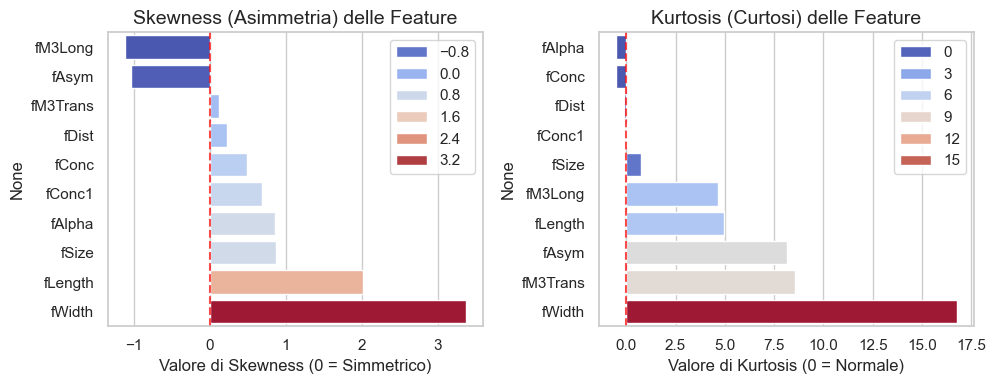

In [3]:
# Impostiamo lo stile dei grafici
sns.set_theme(style="whitegrid")

# 1. Statistiche descrittive di base 
display(df.describe())

# Selezioniamo solo le colonne numeriche
numeric_cols = df.select_dtypes(include=[np.number]).columns

# Calcoliamo Skewness e Kurtosis e li ordiniamo per visualizzarli meglio
skewness = df[numeric_cols].skew().sort_values()
kurtosis = df[numeric_cols].kurtosis().sort_values()

# Creiamo due grafici affiancati
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Grafico Skewness
sns.barplot(x=skewness.values, y=skewness.index, ax=axes[0], palette="coolwarm", hue=skewness.values)
axes[0].axvline(0, color='red', linestyle='--', alpha=0.7) # Linea di riferimento per la simmetria perfetta
axes[0].set_title('Skewness (Asimmetria) delle Feature', fontsize=14)
axes[0].set_xlabel('Valore di Skewness (0 = Simmetrico)')

# Grafico Kurtosis
sns.barplot(x=kurtosis.values, y=kurtosis.index, ax=axes[1], palette="coolwarm", hue=kurtosis.values)
axes[1].axvline(0, color='red', linestyle='--', alpha=0.7) # Linea di riferimento per la curtosi normale (Mesocurtica)
axes[1].set_title('Kurtosis (Curtosi) delle Feature', fontsize=14)
axes[1].set_xlabel('Valore di Kurtosis (0 = Normale)')

plt.tight_layout()
plt.show()

L'immagine mostra due grafici a barre orizzontali che illustrano rispettivamente la **Skewness (Asimmetria)** e la **Kurtosis (Curtosi)** delle diverse feature del dataset.

Dal grafico possiamo trarre due conclusioni importantissime:

1. **Grafico della Skewness (sinistra)**:
   - `fWidth` e `fLength` mostrano valori di skewness fortemente positivi (tra 2.0 e 3.5), indicando una pronunciata asimmetria destra (code lunghe verso i valori alti).
   - Molte feature come `fSize`, `fAlpha`, `fConc1` hanno una skewness moderatamente positiva.
   - `fM3Long` e `fAsym` mostrano una lieve asimmetria negativa (code lunghe verso i valori bassi).

2. **Grafico della Kurtosis (destra)**:
   - `fWidth` presenta un valore di curtosi altissimo (quasi 17), indicando una distribuzione "leptocurtica" estrema, ovvero con un picco molto acuto al centro e code "pesanti" (molti outlier estremi).
   - Anche `fM3Trans`, `fAsym`, `fLength` e `fM3Long` mostrano curtosi elevate (tra 5 e 10), confermando la presenza di code pesanti.
   - Le altre feature, come `fSize` o `fAlpha`, hanno valori più vicini allo zero, indicando distribuzioni con code più simili a quelle di una normale.

Questi grafici confermano visivamente e matematicamente la nostra decisione di applicare una trasformazione logaritmica (nella Parte B) a `fWidth`, `fLength` e `fAlpha` per cercare di rendere queste distribuzioni così "estreme" più gestibili dai modelli di machine learning.

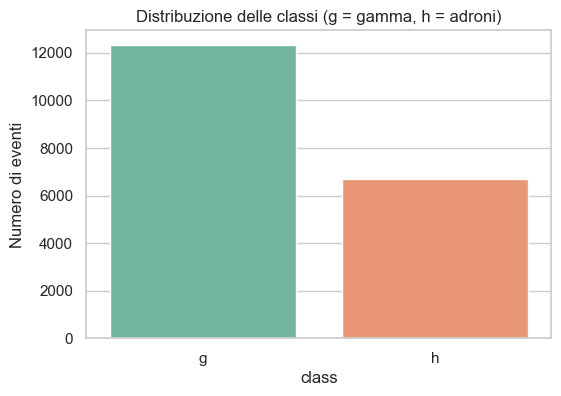

In [4]:
# 2. Distribuzione delle classi
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='class', palette='Set2', hue='class')
plt.title("Distribuzione delle classi (g = gamma, h = adroni)")
plt.ylabel("Numero di eventi")
plt.show()

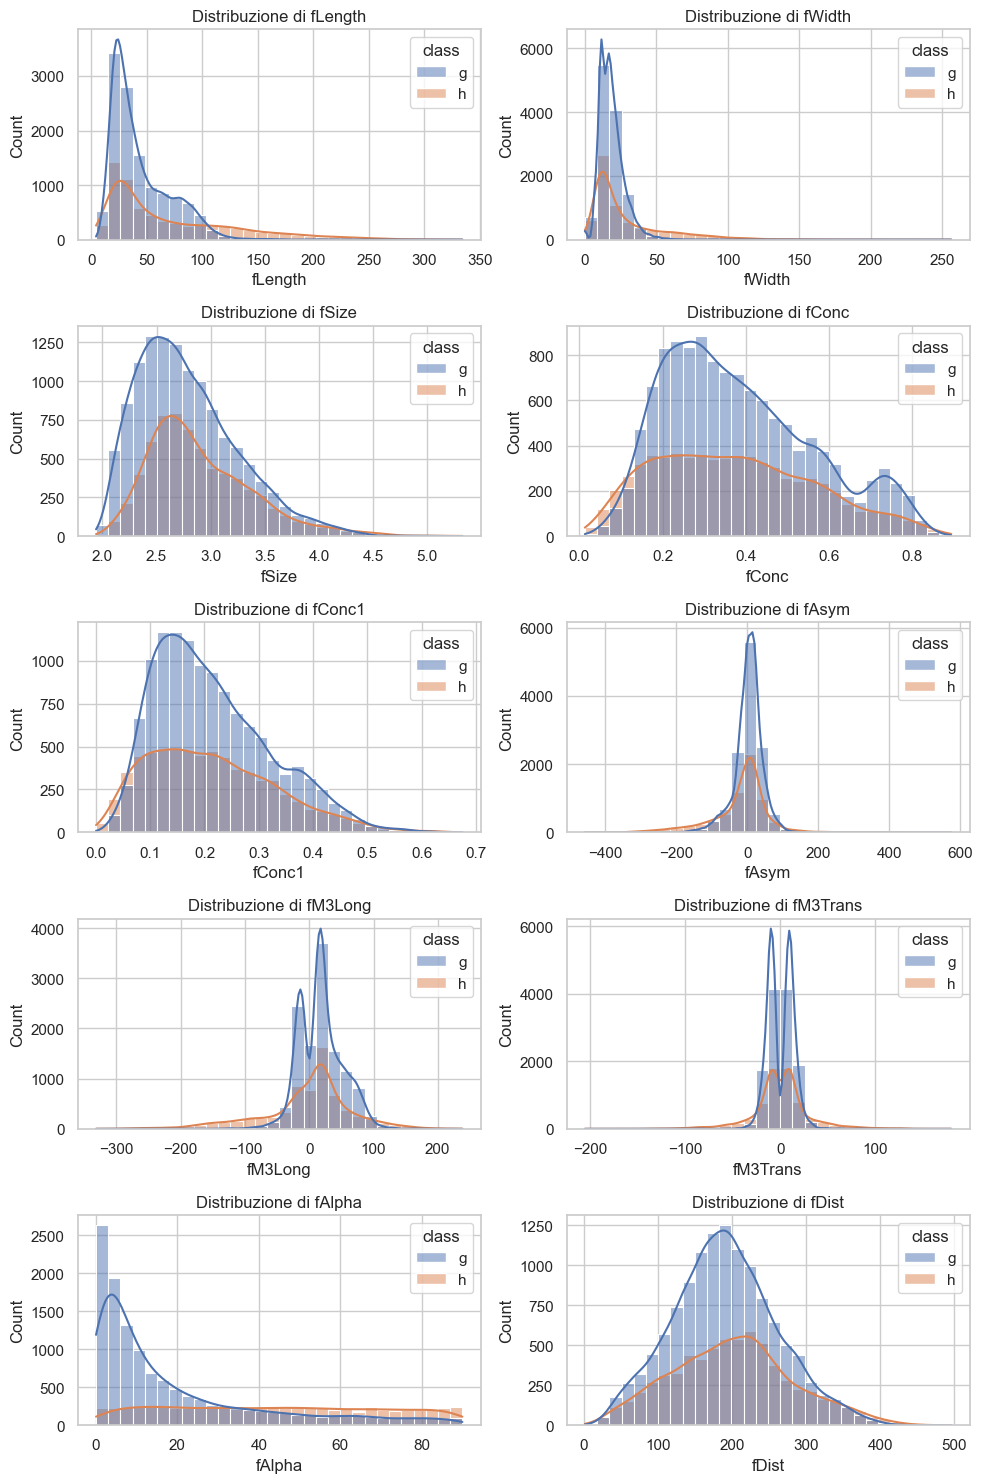

In [5]:
# 3. Distribuzione delle feature numeriche rispetto alla classe
fig, axes = plt.subplots(5, 2, figsize=(10, 15))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(data=df, x=col, hue='class', kde=True, ax=axes[i], bins=30, alpha=0.5)
    axes[i].set_title(f'Distribuzione di {col}')

plt.tight_layout()
plt.show()

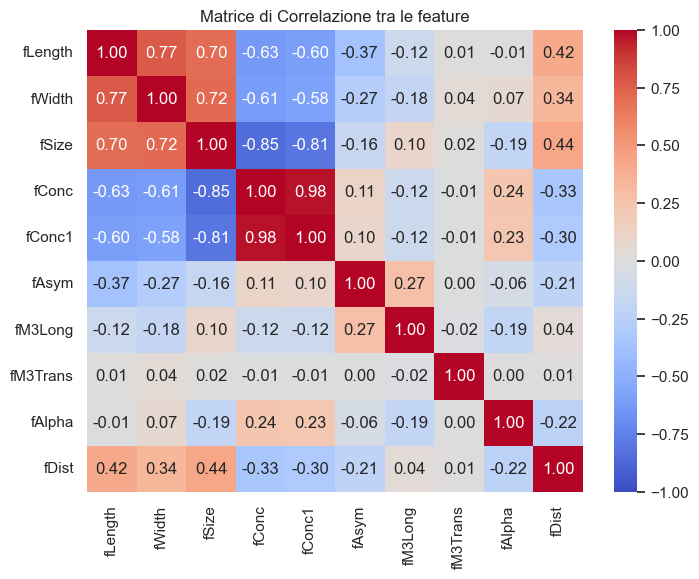

In [6]:
# 4. Matrice di correlazione
plt.figure(figsize=(8, 6))
corr_matrix = df[numeric_cols].corr()

# Disegniamo la heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Matrice di Correlazione tra le feature")
plt.show()

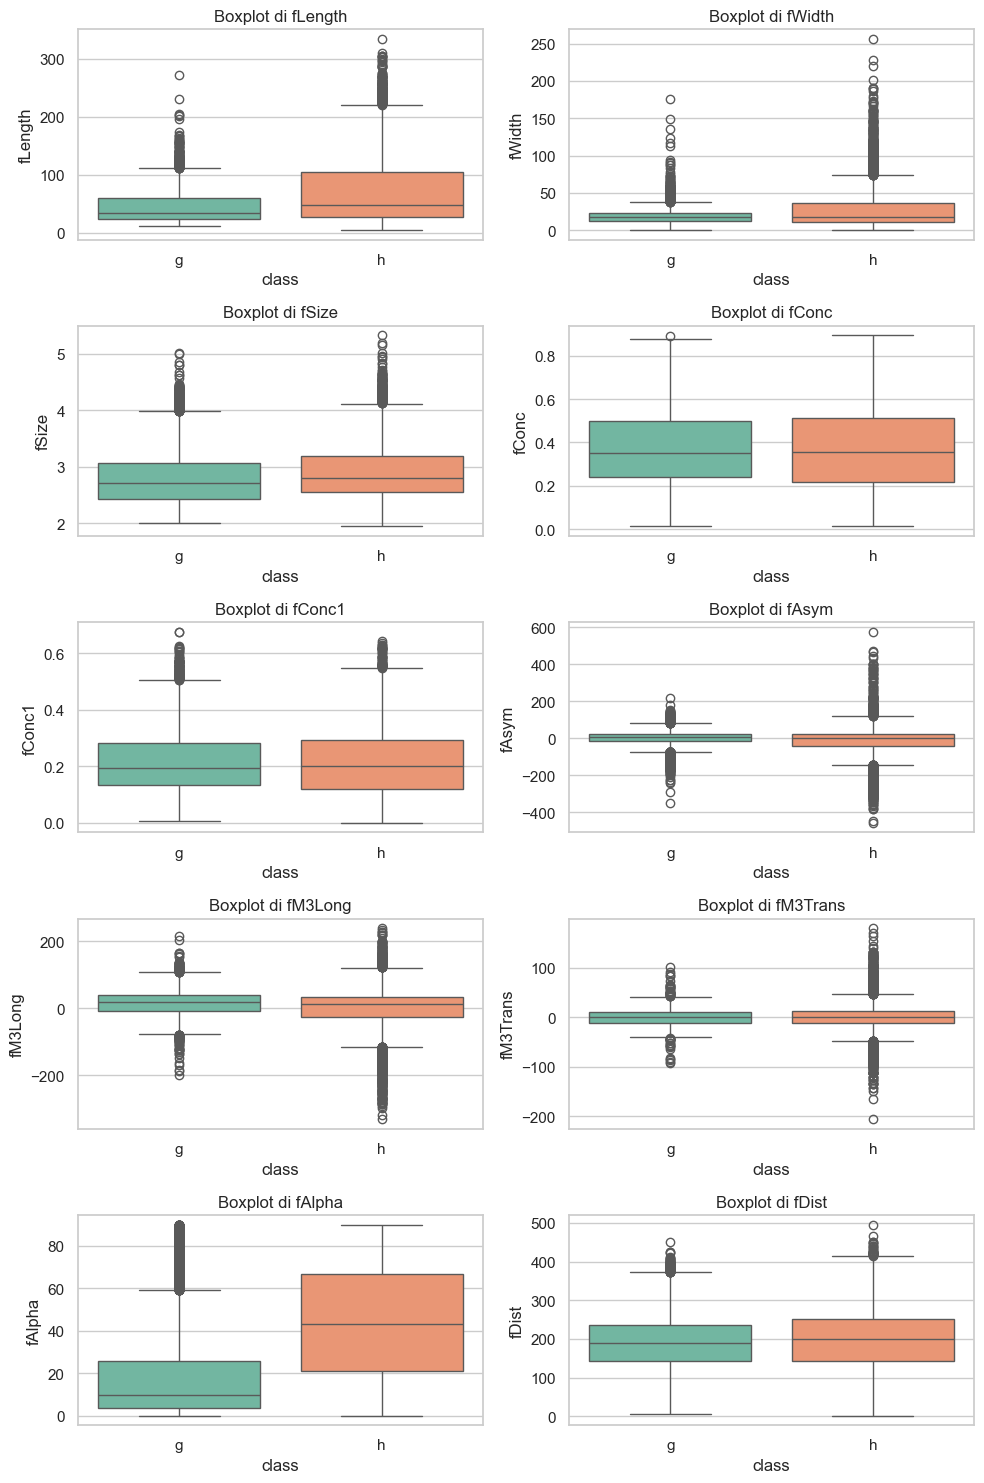

Feature           IQR  Outlier IQR  Outlier Z>3
------------------------------------------------
fLength        45.786          971          431
fWidth         12.876         1546          487
fSize           0.624          367          159
fConc           0.268            0            0
fConc1          0.157          150           99
fAsym          44.650         1781          421
fM3Long        48.681         1218          398
fM3Trans       21.796          850          398
fAlpha         40.336            0            0
fDist          98.072          128           27


In [7]:
# 5. Boxplot per identificazione degli outlier
fig, axes = plt.subplots(5, 2, figsize=(10, 15))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=df, y=col, x='class', ax=axes[i], palette='Set2', hue='class')
    axes[i].set_title(f'Boxplot di {col}')

plt.tight_layout()
plt.show()

# --- Calcolo numerico degli outlier: metodo IQR e Z-score ---
from scipy import stats

print(f"{'Feature':<12} {'IQR':>8} {'Outlier IQR':>12} {'Outlier Z>3':>12}")
print("-" * 48)
for col in numeric_cols:
    # IQR: outlier = valori < Q1 - 1.5*IQR  oppure  > Q3 + 1.5*IQR
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    n_iqr = ((df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)).sum()

    # Z-score: outlier = |z| > 3
    z_scores = np.abs(stats.zscore(df[col]))
    n_z = (z_scores > 3).sum()

    print(f"{col:<12} {IQR:>8.3f} {n_iqr:>12} {n_z:>12}")


**1. Distribuzione delle classi (Sbilanciamento)**
> Guardando il grafico a barre della distribuzione delle classi, si nota un evidente **sbilanciamento del dataset**. La classe `g` (gamma, il nostro segnale) è circa il doppio rispetto alla classe `h` (adroni, il rumore di fondo), con circa 12.000 eventi contro poco più di 6.000. Questo significa che l'accuratezza (accuracy) non sarà da sola una metrica sufficiente per valutare i modelli, ma dovremo affidarci a metriche come F1-Score, Precision, Recall e AUC.

**2. Istogrammi e potere discriminante delle feature**
> Dagli istogrammi sovrapposti, possiamo notare quali variabili separano meglio le due classi:
> * **`fAlpha` è la feature più discriminante in assoluto:** per i raggi gamma (`g`) si concentra fortemente vicino allo zero e decade rapidamente, mentre per il fondo adronico (`h`) ha una distribuzione quasi uniforme.
> * Le feature `fLength` e `fWidth` mostrano per entrambe le classi una forte asimmetria positiva (right-skewed). Gli adroni tendono ad avere code molto più lunghe, indicando ellissi fisicamente più grandi o allungate.
> * Le feature di asimmetria e momento (`fAsym`, `fM3Long`, `fM3Trans`) sono centrate sullo zero, ma gli adroni presentano una varianza molto maggiore (code più larghe) rispetto ai gamma.

**3. Matrice di Correlazione (Multicollinearità)**
> La matrice di correlazione evidenzia forti legami tra alcune variabili:
> * Esiste una **correlazione quasi perfetta (0.98)** tra `fConc` e `fConc1`. Queste due feature misurano essenzialmente la stessa quantità fisica (la concentrazione di luce nei pixel più luminosi). Una delle due è ridondante.
> * `fSize` è fortemente correlata in positivo con le dimensioni dell'ellisse (`fLength` 0.70, `fWidth` 0.72) e in negativo con la concentrazione (`fConc` -0.85). 
> Questa elevata multicollinearità giustifica l'uso della PCA (richiesta nella Parte B) per ridurre la dimensionalità, oltre a suggerire che modelli lineari come la Logistic Regression potrebbero aver bisogno di regolarizzazione.

**4. Analisi degli Outlier**
> I boxplot mostrano una grandissima quantità di "outlier" (punti oltre i baffi), specialmente per `fLength`, `fWidth`, `fSize` e `fAsym`. 
> * **Trattamento degli outlier:** In questo contesto di fisica sperimentale, rimuovere questi valori anomali sarebbe un grave errore. Non si tratta di errori di misurazione, ma di eventi fisici reali (ad esempio, particelle ad altissima energia che creano sciami molto estesi). 
> * Invece di rimuoverli, li tratteremo applicando trasformazioni (es. logaritmo) per ridurre la skewness e scegliendo modelli robusti agli outlier come le Random Forest o il Gradient Boosting.

**Discussione sugli outlier in fisica**
> *In un contesto di fisica sperimentale (e in particolare per l'astrofisica delle particelle), gli "outlier" (valori estremi) non rappresentano necessariamente degli errori di misurazione del sensore. Potrebbero infatti corrispondere a sciami atmosferici generati da raggi gamma o cosmici ad altissima energia, oppure a eventi rari ma fisicamente reali.* 
> *Rimuovere ciecamente gli outlier con regole standard (come tagliare i valori oltre i baffi del boxplot, IQR) rischierebbe di scartare le osservazioni dei fenomeni fisici più estremi e interessanti. Pertanto, è consigliabile **non rimuoverli**, ma piuttosto utilizzare in fase di pre-processing trasformazioni che ne mitighino l'impatto (come la trasformazione logaritmica richiesta nella Parte B) e scegliere modelli di classificazione resistenti agli outlier (come i modelli ad albero, es. Random Forest).*

In [8]:
# 3. Codifica della label in formato binario (g -> 1: segnale, h -> 0: fondo)
df['class'] = df['class'].map({'g': 1, 'h': 0})

# Separare feature (X) e target (y)
X = df.drop('class', axis=1)
y = df['class']

In [9]:
# 1. Applicazione della trasformazione logaritmica (log1p calcola log(1+x) per evitare log(0))
# Dal grafico precedente abbiamo visto che fLength, fWidth e fAlpha sono molto asimmetriche (right-skewed)
cols_to_log = ['fLength', 'fWidth', 'fAlpha']

# Creiamo una copia per non modificare l'originale inavvertitamente
X_transformed = X.copy()
for col in cols_to_log:
    # Usiamo np.log1p per gestire in sicurezza eventuali valori pari a 0
    X_transformed[col] = np.log1p(X_transformed[col])

In [10]:
# 2. Standardizzazione delle feature
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_transformed), columns=X_transformed.columns)

In [11]:
# Visualizziamo le prime righe del dataset trasformato e standardizzato
display(X_scaled.head())

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist
0,-0.549029,-0.181231,-0.381130,0.062759,-0.148923,0.541042,0.224818,-0.405842,0.774965,-1.497866
1,-0.413134,-0.653062,-0.648595,0.820383,1.471776,0.516919,0.260364,-0.490094,-0.671404,0.153125
2,2.016653,3.215443,2.615783,-1.875883,-1.773241,2.044992,-1.478536,-2.183030,1.313585,0.842635
3,-0.825060,-0.954446,-1.029478,1.282069,1.606608,0.532771,-0.333515,-0.355359,-0.299876,-1.031463
4,0.867088,0.844038,0.711157,-0.347506,-0.284660,-0.020200,0.353086,1.036620,-0.894193,2.176427


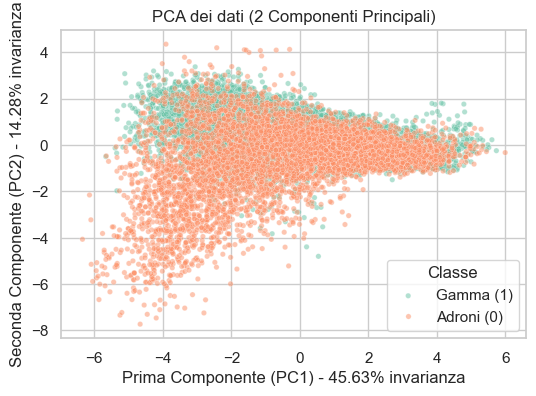

In [12]:
# 4. Effettuare una riduzione dimensionale con PCA a 2 componenti
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Creazione di un DataFrame per la visualizzazione
df_pca = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
df_pca['class'] = y.values

# Plot
plt.figure(figsize=(6, 4))
sns.scatterplot(
    data=df_pca, x='PC1', y='PC2', hue='class', 
    palette={1: '#66c2a5', 0: '#fc8d62'}, alpha=0.5, s=15
)
plt.title('PCA dei dati (2 Componenti Principali)')
plt.xlabel(f'Prima Componente (PC1) - {pca.explained_variance_ratio_[0]*100:.2f}% invarianza')
plt.ylabel(f'Seconda Componente (PC2) - {pca.explained_variance_ratio_[1]*100:.2f}% invarianza')
# Modifica la legenda per renderla più chiara
plt.legend(title='Classe', labels=['Gamma (1)', 'Adroni (0)'])
plt.show()


> **Giustificazione delle scelte:**
> * **Label Encoding:** Abbiamo mappato la classe `g` (segnale gamma) al valore `1` e `h` (fondo adronico) a `0`, impostando il problema come classificazione binaria dove il nostro obiettivo è identificare i gamma.
> * **Trasformazioni (Log-transform):** Variabili come `fLength`, `fWidth` e `fAlpha` presentano una forte asimmetria (code lunghe verso destra). Abbiamo applicato una trasformazione logaritmica (`np.log1p`) per "schiacciare" queste code. Questo riduce l'impatto degli outlier estremi senza eliminarli (essendo eventi fisici reali) e rende le distribuzioni più simili a una gaussiana, aiutando i modelli lineari.
> * **Standardizzazione:** Modelli come la Logistic Regression, SVM e KNN calcolano le distanze o usano gradienti che sono molto sensibili alla scala delle variabili. Portando tutte le feature a media 0 e varianza 1 (`StandardScaler`), garantiamo che nessuna feature domini sulle altre solo perché misurata su una scala numerica più grande.

**Commento sulla PCA**
> Le prime due componenti principali spiegano insieme circa il 60% della varianza totale (45.63% + 14.28%). Visivamente, i segnali gamma (verdi) formano un cluster molto compatto e denso nella parte medio-alta, mentre il rumore adronico (arancione) ha una varianza molto più ampia, sparpagliandosi soprattutto verso i valori negativi di PC2 e PC1. Poiché c'è una vasta area di sovrapposizione, un separatore lineare (es. Logistic Regression) non sarà sufficiente; ci aspettiamo risultati migliori da modelli non lineari.
> La separazione non è netta e lineare in sole 2 dimensioni: questo suggerisce che un semplice classificatore lineare (come la Logistic Regression) potrebbe faticare a isolare perfettamente le classi, mentre modelli non lineari o basati su alberi (Random Forest, Gradient Boosting) potrebbero ottenere performance migliori catturando le complesse interazioni multi-dimensionali.

**Perché PCA e non t-SNE / UMAP?**
> Sono state considerate anche le alternative non lineari t-SNE e UMAP, che in molti casi riescono a separare visivamente le classi in modo più netto. Tuttavia, per questa analisi si è preferita la PCA per tre ragioni: (1) le componenti principali sono direttamente **interpretabili** come combinazioni lineari delle feature originali, il che permette di capire quali variabili fisiche "pesano" di più; (2) la PCA è **deterministica e stabile**, mentre t-SNE dipende fortemente dall'iperparametro `perplexity` e produce embedding diversi ad ogni esecuzione; (3) l'obiettivo qui è valutare la **separabilità lineare** dei dati in bassa dimensione, un'informazione che la PCA fornisce in modo diretto tramite la varianza spiegata. t-SNE o UMAP sarebbero preferibili se l'obiettivo fosse la visualizzazione esplorativa di strutture a cluster, non la valutazione della separabilità.


In [13]:
# 5. Suddividere il dataset in train/validation/test con stratificazione
# Prima divisione: separiamo il Test set (20%) dal resto (80%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X_scaled, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y # <- Fondamentale per mantenere la proporzione g/h
)

# Seconda divisione: dividiamo il restante 80% in Train (60% del totale) e Validation (20% del totale)
# Per ottenere un 20% del totale partendo dall'80%, la proporzione è 20/80 = 0.25 (25%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, 
    test_size=0.25, 
    random_state=42, 
    stratify=y_temp
)

print(f"Dimensioni del Train set:      {X_train.shape[0]} campioni ({len(X_train)/len(df)*100:.0f}%)")
print(f"Dimensioni del Validation set: {X_val.shape[0]} campioni ({len(X_val)/len(df)*100:.0f}%)")
print(f"Dimensioni del Test set:       {X_test.shape[0]} campioni ({len(X_test)/len(df)*100:.0f}%)")

Dimensioni del Train set:      11412 campioni (60%)
Dimensioni del Validation set: 3804 campioni (20%)
Dimensioni del Test set:       3804 campioni (20%)


In [14]:
# Dizionario per salvare i risultati dei modelli e le predizioni
results = {}
best_models = {}

# 1. LOGISTIC REGRESSION
print("Addestramento Logistic Regression...")
lr = LogisticRegression(max_iter=1000, random_state=42)
param_lr = {'C': [0.01, 0.1, 1, 10, 100]}
search_lr = RandomizedSearchCV(lr, param_distributions=param_lr, 
                               n_iter=5, 
                               cv=3, 
                               scoring='f1', 
                               random_state=42, 
                               n_jobs=-1)
search_lr.fit(X_train, y_train)
best_models['Logistic Regression'] = search_lr.best_estimator_

# 2. RANDOM FOREST
print("Addestramento Random Forest...")
rf = RandomForestClassifier(random_state=42)
param_rf = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}
search_rf = RandomizedSearchCV(rf, param_distributions=param_rf, 
                               n_iter=5, 
                               cv=3, 
                               scoring='f1', 
                               random_state=42, 
                               n_jobs=-1)
search_rf.fit(X_train, y_train)
best_models['Random Forest'] = search_rf.best_estimator_

# 3. GRADIENT BOOSTING
print("Addestramento Gradient Boosting...")
gb = GradientBoostingClassifier(random_state=42)
param_gb = {
    'n_estimators': [100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}
search_gb = RandomizedSearchCV(gb, param_distributions=param_gb, 
                               n_iter=5, 
                               cv=3, 
                               scoring='f1', 
                               random_state=42, 
                               n_jobs=-1)
search_gb.fit(X_train, y_train)
best_models['Gradient Boosting'] = search_gb.best_estimator_

print("\nAddestramento completato!")

Addestramento Logistic Regression...
Addestramento Random Forest...
Addestramento Gradient Boosting...

Addestramento completato!


--- Logistic Regression ---
Accuracy:  0.8160 | Precision: 0.8181
Recall:    0.9209 | F1-Score:  0.8665
ROC-AUC:   0.8602

--- Random Forest ---
Accuracy:  0.8778 | Precision: 0.8777
Recall:    0.9428 | F1-Score:  0.9091
ROC-AUC:   0.9361

--- Gradient Boosting ---
Accuracy:  0.8785 | Precision: 0.8790
Recall:    0.9424 | F1-Score:  0.9096
ROC-AUC:   0.9335



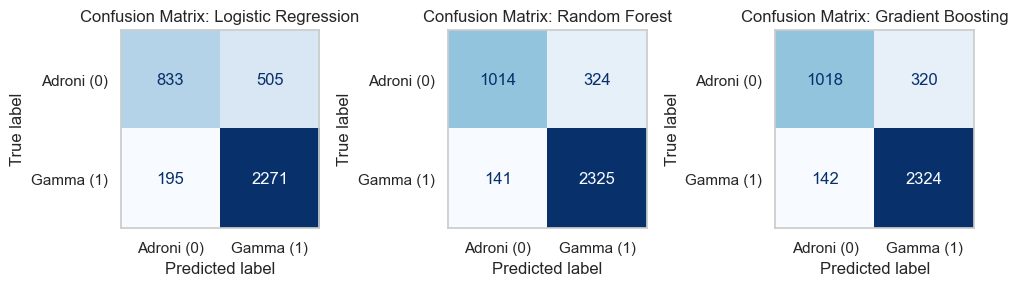

In [15]:
# Valutazione
fig, axes = plt.subplots(1, 3, figsize=(10, 3))

for i, (name, model) in enumerate(best_models.items()):
    # Predizioni
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    # Calcolo metriche
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    
    # Salviamo i risultati per la tabella finale e i plot
    results[name] = {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1, 'ROC-AUC': auc, 'probs': y_prob}
    
    # Stampa risultati
    print(f"--- {name} ---")
    print(f"Accuracy:  {acc:.4f} | Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f} | F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {auc:.4f}\n")
    
    # Plot Matrice di Confusione
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Adroni (0)', 'Gamma (1)'])
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(f'Confusion Matrix: {name}')
    axes[i].grid(False)

plt.tight_layout()
plt.show()

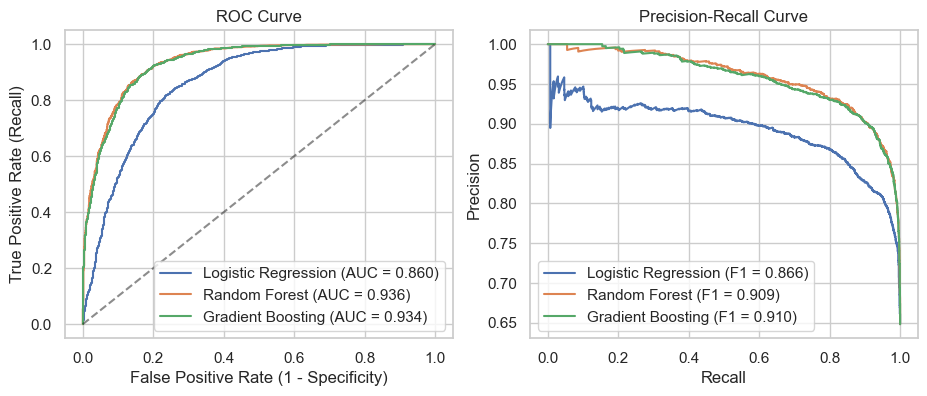

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

for name, res in results.items():
    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, res['probs'])
    ax1.plot(fpr, tpr, label=f"{name} (AUC = {res['ROC-AUC']:.3f})")
    
    # Precision-Recall Curve
    precision, recall, _ = precision_recall_curve(y_test, res['probs'])
    ax2.plot(recall, precision, label=f"{name} (F1 = {res['F1-Score']:.3f})")

# Dettagli plot ROC
ax1.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax1.set_title('ROC Curve')
ax1.set_xlabel('False Positive Rate (1 - Specificity)')
ax1.set_ylabel('True Positive Rate (Recall)')
ax1.legend()

# Dettagli plot Precision-Recall
ax2.set_title('Precision-Recall Curve')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.legend()

plt.show()


> **Discussione sulle Metriche nell'Esperimento MAGIC**
> In un esperimento reale con telescopi Cherenkov, il flusso di raggi cosmici adronici (rumore di fondo) è immensamente superiore al flusso di raggi gamma (il nostro segnale di interesse). 
> * **Un Falso Negativo** significa classificare un evento gamma come se fosse un adrone: questo comporta la perdita di un frammento di segnale (si riduce la statistica), che è un danno accettabile.
> * **Un Falso Positivo** significa classificare un adrone (rumore) come se fosse un raggio gamma: se abbiamo troppi falsi positivi, il nostro catalogo di raggi gamma diventerà "sporco" e inquinato dal rumore, falsando completamente le misurazioni astronomiche e la scoperta di nuove sorgenti gamma.
> 
> **Conclusione:** In questo contesto, **è molto più costoso un Falso Positivo**. Pertanto, la **Precisione** (capacità di non inquinare il segnale) e la **Specificità** sono metriche cruciali, più importanti della Recall. Desideriamo un modello con una Precisione molto alta, accettando un compromesso sulla Recall se necessario. La curva Precision-Recall è quindi lo strumento diagnostico più utile per valutare i nostri classificatori in questo specifico task.


## Confronto dei Modelli  

**Tabella Comparativa dei Risultati (sul Test Set):**

| Modello | Falsi Positivi (FP) | Falsi Negativi (FN) | F1-Score | ROC-AUC |
|:---|:---:|:---:|:---:|:---:|
| **Logistic Regression** | 505 | 195 | 0.866 | 0.860 |
| **Random Forest** | 324 | 141 | 0.909 | **0.936** |
| **Gradient Boosting** | **320** | **142** | **0.910** | 0.934 |

In [19]:
import xgboost as xgb
from sklearn.metrics import classification_report

print("Addestramento XGBoost Extreme Gradient Boosting...")

# 1. Definiamo il modello XGBoost
xgb_model = xgb.XGBClassifier(
    random_state=42, 
    eval_metric='logloss',
)

# 2. Griglia di iperparametri un po' più avanzata
param_xgb = {
    'n_estimators': [200, 300],
    'learning_rate': [0.05, 0.1],
    'max_depth': [5, 7, 9],
    'subsample': [0.8, 1.0],        # Usa un sottoinsieme di dati (previene overfitting)
    'colsample_bytree': [0.8, 1.0]  # Usa un sottoinsieme di feature per ogni albero
}

# Ricerca randomizzata
search_xgb = RandomizedSearchCV(
    xgb_model, param_distributions=param_xgb, 
    n_iter=10, cv=3, scoring='f1', random_state=42, n_jobs=-1
)

search_xgb.fit(X_train, y_train)
best_xgb = search_xgb.best_estimator_

# Valutazione base (soglia al 50%)
y_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]
y_pred_xgb_default = (y_prob_xgb >= 0.5).astype(int)

auc_xgb = roc_auc_score(y_test, y_prob_xgb)
print(f"XGBoost AUC: {auc_xgb:.4f}")

Addestramento XGBoost Extreme Gradient Boosting...
XGBoost AUC: 0.9385


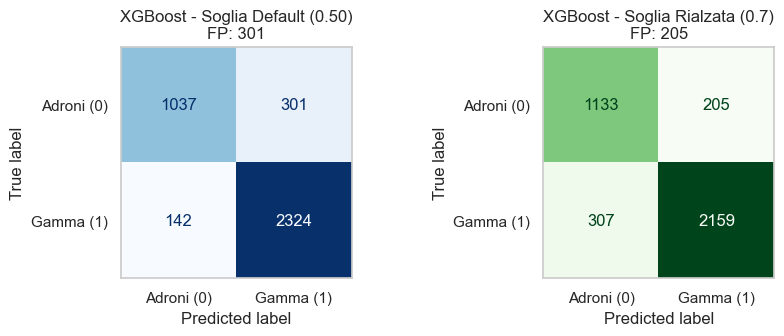

In [20]:
# 3. THRESHOLD TUNING
# Vogliamo ridurre i Falsi Positivi. Alziamo la soglia a 0.70!
soglia_personalizzata = 0.70
y_pred_xgb_custom = (y_prob_xgb >= soglia_personalizzata).astype(int)

# Calcoliamo le nuove matrici di confusione
cm_default = confusion_matrix(y_test, y_pred_xgb_default)
cm_custom = confusion_matrix(y_test, y_pred_xgb_custom)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))

# Plot CM Default
ConfusionMatrixDisplay(cm_default, display_labels=['Adroni (0)', 'Gamma (1)']).plot(ax=ax1, cmap='Blues', colorbar=False)
ax1.set_title(f'XGBoost - Soglia Default (0.50)\nFP: {cm_default[0,1]}')
ax1.grid(False)

# Plot CM Custom
ConfusionMatrixDisplay(cm_custom, display_labels=['Adroni (0)', 'Gamma (1)']).plot(ax=ax2, cmap='Greens', colorbar=False)
ax2.set_title(f'XGBoost - Soglia Rialzata ({soglia_personalizzata})\nFP: {cm_custom[0,1]}')
ax2.grid(False)

plt.show()

Utilizzando XGBoost abbiamo leggermente migliorato il potere predittivo grezzo (AUC). Tuttavia, il vero salto di qualità per un esperimento come MAGIC si ottiene manipolando la soglia decisionale. Alzando la soglia di classificazione dal 50% al 70%, il modello classifica un evento come "Gamma" solo quando ne è altamente sicuro.


- A sinistra (matrice blu): È il risultato del modello con la soglia di default (0.50). Identifica correttamente 1037 eventi di fondo (Adroni) e ben 2324 eventi di segnale (Gamma). Tuttavia, produce 301 Falsi Positivi (rumore di fondo scambiato per segnale gamma) e 142 Falsi Negativi (segnale perso).

- A destra (matrice verde): È il risultato dello stesso modello, ma con la soglia rialzata (0.70). Qui si vede esattamente l'effetto della strategia discussa: diventando più "severo", il modello classifica molti più adroni in modo corretto (1133 veri negativi) e fa crollare i Falsi Positivi a soli 205 (quasi 100 "falsi allarmi" in meno!). Come previsto, il compromesso è l'aumento dei Falsi Negativi a 307 (perdiamo qualche segnale gamma vero), ma il campione classificato come "Gamma" è ora molto più puro.


### Sintesi e Principali Take-away

L'analisi ha dimostrato che il problema di classificazione tra segnali gamma e rumore adronico è intrinsecamente non lineare, come ipotizzato durante la PCA. Infatti, il modello lineare di baseline (Logistic Regression) ha ottenuto le performance peggiori, faticando a rigettare il fondo e producendo ben 505 Falsi Positivi. 

I modelli basati su alberi decisionali (Random Forest e Gradient Boosting) hanno performato in modo eccellente e quasi identico, superando entrambi un ROC-AUC di 0.93. 

Considerando l'esigenza fisica di minimizzare l'inquinamento del segnale da parte del rumore di fondo (ridurre i Falsi Positivi per massimizzare la Purity/Precision), **il modello vincitore è il Gradient Boosting**. Esso presenta il minor numero di Falsi Positivi (320), il miglior F1-Score (0.910) e una curva Precision-Recall superiore, garantendo la migliore reiezione del fondo adronico senza perdere troppi eventi gamma reali.

Il take-away fondamentale risiede però nell'interpretazione del dominio fisico: per non inquinare le misurazioni astrofisiche, è cruciale minimizzare i **Falsi Positivi** massimizzando la **Precisione**. In quest'ottica, la strategia vincente è stata l'applicazione di **XGBoost con una soglia decisionale rialzata (0.70)**: questa scelta metodologica ha permesso di abbattere drasticamente i falsi allarmi del fondo adronico, garantendo un campione di segnale gamma altamente puro al costo di una tollerabile riduzione della Recall.